# INF201 Deliverable 1: Weather data from Frost

**Authors:** Amena and Arthika

**GitHub repository:** https://github.com/amhus8955/INF201_deliverable_1

In this notebook we get daily weather data for station SN17850 (Ås) from the Frost API at the Norwegian Meteorological Institute (https://frost.met.no). Tasks 1–3 look at temperature, precipitation and temperature in 1925 compared to 2025. Task 4 finds heatwaves in 2025, and task 5 calculates a 7-day moving average.

We used the Python example from MET as a starting point: https://frost.met.no/python_example.html

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import requests


CLIENT_ID_PATH = '/Users/amenahussain/frost_credentials.txt'
ENDPOINT = 'https://frost.met.no/observations/v0.jsonld'
STATION = 'SN17850'
TEMPERATURE = 'mean(air_temperature P1D)'
PRECIPITATION = 'sum(precipitation_amount P1D)'


def read_client_id(path: str) -> str:
    """
    Read the Frost client ID from a text file.

    Parameters
    ----------
    path : str
        Path to a file that contains only the client ID.

    Returns
    -------
    str
        The client ID without spaces or newlines.
    """
    with open(path) as f:
        # Frost gives "invalid client ID syntax" if anything extra is left.
        return f.read().strip()


def whole_year(year: int) -> str:
    """
    Make a Frost time period that covers one whole year.
    Frost wants time periods written as 'start/end'.
    This function builds that text so the same rule is not written
    by hand for every year that is fetched.

    Parameters
    ----------
    year : int
        The year, e.g. 2025.

    Returns
    -------
    str
        Period as 'start/end', e.g. '2025-01-01/2026-01-01'.
    """
    # The end date is not included in Frost. With '2025-12-31' as end date
    # I only got 364 days, so the period ends on 1 January the year after.
    return f'{year}-01-01/{year + 1}-01-01'


def fetch_data(client_id: str, source: str, element: str,
               reference_time: str) -> list[dict]:
    """
    Request observations of one element from Frost.
    The function sends a request over the internet to Frost to check that
    the answer is ok, and returns only the part of the answer that
    holds the measurements.

    Parameters
    ----------
    client_id : str
        Personal client ID for frost.met.no.
    source : str
        ID of the weather station, e.g. 'SN17850'.
    element : str
        What to measure, e.g. 'mean(air_temperature P1D)'.
    reference_time : str
        Time period as 'start/end'. The end date is not included.

    Returns
    -------
    list[dict]
        One dictionary per day, as returned by Frost.

    Raises
    ------
    RuntimeError
        If Frost does not return status code 200.
    """
    parameters = {
        'sources': source,
        'elements': element,
        'referencetime': reference_time,
    }
    r = requests.get(ENDPOINT, parameters, auth=(client_id, ''))
    json_data = r.json()

    if r.status_code != 200:
        message = json_data['error']['message']
        reason = json_data['error']['reason']
        raise RuntimeError(
            f'Error {r.status_code}: {message}. Reason: {reason}'
        )

    print(f'Data retrieved: {element}, {reference_time}')
    return json_data['data']


def make_dataframe(data: list[dict]) -> pd.DataFrame:
    """
    Convert the data from Frost into a DataFrame with one row per day.
    The data from Frost is nested;
    each day has a date and a list of observations inside.
    A DataFrame is a flat table which is much easier to
    calculate statistics from and to plot.

    Parameters
    ----------
    data : list[dict]
        Data returned by fetch_data().

    Returns
    -------
    pd.DataFrame
        Columns: referenceTime, value, unit and timeOffset.
    """
    rows = []
    for day in data:
        row = pd.DataFrame(day['observations'])
        row['referenceTime'] = day['referenceTime']
        rows.append(row)

    # MET's example uses df.append(), which is removed in newer pandas.
    # pd.concat() does the same, and joining once at the end is faster.
    df = pd.concat(rows, ignore_index=True)

    df = df[['referenceTime', 'value', 'unit', 'timeOffset']].copy()
    # Convert text to datetime, so matplotlib treats it as dates.
    df['referenceTime'] = pd.to_datetime(df['referenceTime'])

    # Frost can give more than one value per day (different timeOffset).
    # Keep one per day, so no day is counted twice in the statistics.
    return df.drop_duplicates(subset='referenceTime')

In [2]:
def plot_temperatures(dfs: dict[str, pd.DataFrame], title: str) -> None:
    """
    Plot one or more temperature series in the same figure.

    Used for both Task 1 (one year) and Task 3 (two years). When several
    years are plotted, their dates must be in the same year, so that the
    same day of the year is placed at the same point on the x-axis.

    Parameters
    ----------
    dfs : dict[str, pd.DataFrame]
        Legend text as key, DataFrame with referenceTime and value as
        value. Series are drawn in the order they are given.
    title : str
        Title of the plot.
    """
    fig, ax = plt.subplots(figsize=(12, 5))  # wide, since it covers a year
    for label, df in dfs.items():
        # Slightly transparent, so overlapping lines can still be seen.
        ax.plot(df['referenceTime'], df['value'], linewidth=1.2,
                alpha=0.85, label=label)
    # Dashed line at 0 °C shows which days were below freezing.
    ax.axhline(0, color='grey', linestyle='--', linewidth=0.8)

    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Month')
    ax.set_ylabel('Temperature (°C)')
    # Only month names are shown. In Task 3 the year on the axis is not
    # the real year for the old data, so showing it would be misleading.
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    ax.grid(alpha=0.3)
    # A legend is only useful when there is more than one line.
    if len(dfs) > 1:
        ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


def plot_temperature_and_precipitation(df_temp: pd.DataFrame,
                                       df_precip: pd.DataFrame,
                                       title: str) -> None:
    """
    Plot temperature and precipitation in the same figure.

    Showing both in one figure makes it possible to compare them day by
    day, e.g. to see if rainy days tend to be warm or cold.

    Parameters
    ----------
    df_temp : pd.DataFrame
        Daily temperature, columns referenceTime and value.
    df_precip : pd.DataFrame
        Daily precipitation, columns referenceTime and value.
    title : str
        Title of the plot.
    """
    fig, ax_temp = plt.subplots(figsize=(12, 5))
    # Temperature (°C) and precipitation (mm) have different units, so
    # precipitation gets its own y-axis on the right. Both share time.
    ax_precip = ax_temp.twinx()

    # Precipitation is a total amount per day, so bars fit better than a
    # line, which would suggest values between the days.
    ax_precip.bar(df_precip['referenceTime'], df_precip['value'],
                  width=1, color='tab:blue', alpha=0.5,
                  label='Precipitation')
    # Temperature changes gradually, so a line shows the trend well.
    ax_temp.plot(df_temp['referenceTime'], df_temp['value'],
                 color='tab:red', linewidth=1.2, label='Temperature')
    ax_temp.axhline(0, color='grey', linestyle='--', linewidth=0.8)

    # twinx() draws the second axis on top. Move the temperature axis to
    # the front so the line is not hidden behind the bars.
    ax_temp.set_zorder(ax_precip.get_zorder() + 1)
    ax_temp.patch.set_visible(False)

    ax_temp.set_title(title, fontsize=14)
    ax_temp.set_xlabel('Month')
    # Axis labels in the same colour as the data, so it is clear which
    # axis belongs to which measurement.
    ax_temp.set_ylabel('Temperature (°C)', color='tab:red')
    ax_precip.set_ylabel('Precipitation (mm)', color='tab:blue')
    ax_temp.xaxis.set_major_locator(mdates.MonthLocator())
    ax_temp.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    ax_temp.grid(alpha=0.3)

    # Each axis has its own legend, so they are combined into one.
    lines_t, labels_t = ax_temp.get_legend_handles_labels()
    lines_p, labels_p = ax_precip.get_legend_handles_labels()
    ax_temp.legend(lines_t + lines_p, labels_t + labels_p, loc='upper left')

    plt.tight_layout()
    plt.show()


def make_summary(temps: dict[str, pd.Series]) -> pd.DataFrame:
    """
    Make a summary table with mean, median, min and max.

    Used for both Task 1 (one year) and Task 3 (two years).
    Each year becomes its own column, so the years can be compared side
    by side.

    Parameters
    ----------
    temps : dict[str, pd.Series]
        Column name as key, daily temperatures as value.

    Returns
    -------
    pd.DataFrame
        One row per statistic and one column per temperature series.
    """
    # Both mean and median are included: the mean is affected by very
    # cold or warm days, the median is not.
    stats = ['mean', 'median', 'min', 'max']
    summary = pd.DataFrame({'Statistic': ['Mean', 'Median', 'Min', 'Max']})
    for label, temp in temps.items():
        # .agg() calculates all four at once, in the same order as above.
        summary[f'{label} (°C)'] = temp.agg(stats).to_numpy()
    return summary


def print_summary(summary: pd.DataFrame) -> None:
    """
    Print a summary table in a readable format.

    Parameters
    ----------
    summary : pd.DataFrame
        Table made by make_summary().
    """
    # index=False hides row numbers, one decimal matches the data.
    print(summary.to_string(index=False, float_format='%.1f'))


def main() -> None:
    """Run Task 1, 2 and 3."""
    client_id = read_client_id(CLIENT_ID_PATH)

    # The 2025 temperature is used in all three tasks, so it is only
    # retrieved once instead of once per task.
    df_2025 = make_dataframe(fetch_data(client_id, STATION, TEMPERATURE,
                                        whole_year(2025)))
    print('Number of days (temperature 2025):', len(df_2025))

    # Task 1: Temperature
    print('\n--- Task 1: Temperature ---')
    plot_temperatures({'2025': df_2025},
                      'Daily mean air temperature in 2025 (SN17850, Ås)')
    print_summary(make_summary({'2025': df_2025['value']}))

    # Task 2: Precipitation
    print('\n--- Task 2: Precipitation ---')
    df_precip = make_dataframe(fetch_data(client_id, STATION, PRECIPITATION,
                                          whole_year(2025)))
    print('Number of days (precipitation 2025):', len(df_precip))
    plot_temperature_and_precipitation(
        df_2025, df_precip,
        'Temperature and precipitation in 2025 (SN17850, Ås)'
    )

    # Task 3: Historical temperature data
    print('\n--- Task 3: Historical temperature data ---')
    df_1925 = make_dataframe(fetch_data(client_id, STATION, TEMPERATURE,
                                        whole_year(1925)))
    print('Number of days (temperature 1925):', len(df_1925))

    # The statistics only use the values, so they are calculated first.
    summary = make_summary({'1925': df_1925['value'],
                            '2025': df_2025['value']})
    # A positive difference means it was warmer in 2025.
    summary['Difference (°C)'] = summary['2025 (°C)'] - summary['1925 (°C)']
    print_summary(summary)

    # Without this, 1925 and 2025 would be plotted 100 years apart.
    # Moving the old dates forward puts the same day of the year at the
    # same place on the x-axis. Neither year is a leap year, so the dates
    # match exactly. Only the dates change, not the temperatures.
    df_1925['referenceTime'] = (df_1925['referenceTime']
                                + pd.DateOffset(years=100))
    # 1925 is drawn first, so the 2025 line is on top.
    plot_temperatures({'1925': df_1925, '2025': df_2025},
                      'Daily mean air temperature in Ås (SN17850), '
                      '1925 vs 2025')

Data retrieved: mean(air_temperature P1D), 2025-01-01/2026-01-01
Number of days (temperature 2025): 365

--- Task 1: Temperature ---


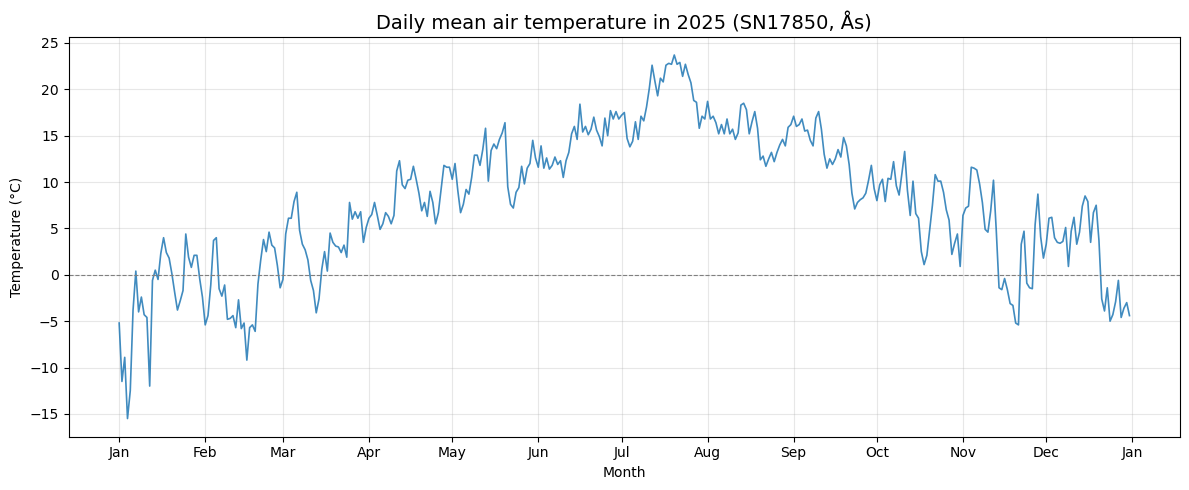

Statistic  2025 (°C)
     Mean        7.9
   Median        8.3
      Min      -15.5
      Max       23.7

--- Task 2: Precipitation ---
Data retrieved: sum(precipitation_amount P1D), 2025-01-01/2026-01-01
Number of days (precipitation 2025): 365


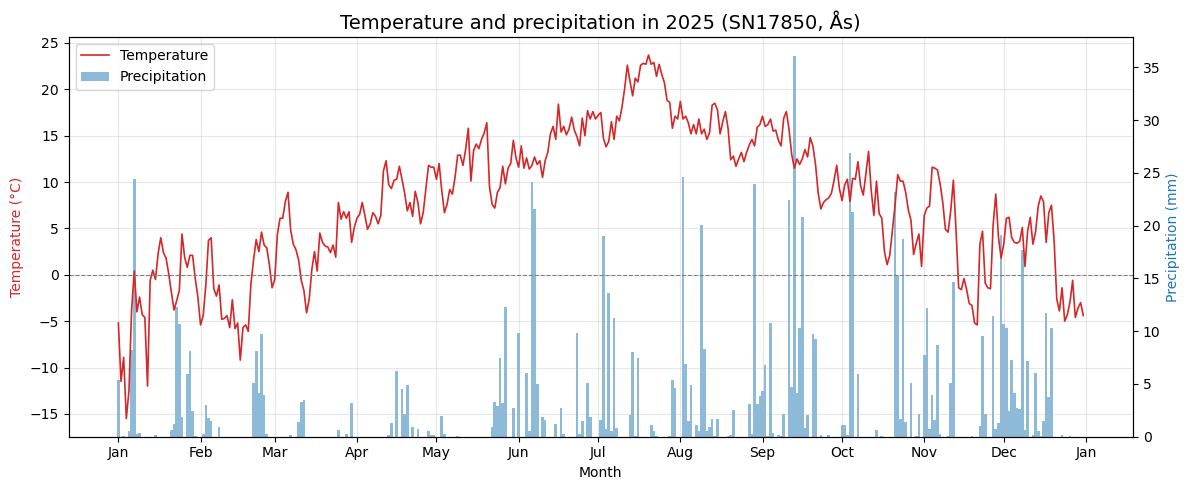


--- Task 3: Historical temperature data ---
Data retrieved: mean(air_temperature P1D), 1925-01-01/1926-01-01
Number of days (temperature 1925): 365
Statistic  1925 (°C)  2025 (°C)  Difference (°C)
     Mean        5.3        7.9              2.6
   Median        5.3        8.3              3.0
      Min      -20.7      -15.5              5.2
      Max       24.3       23.7             -0.6


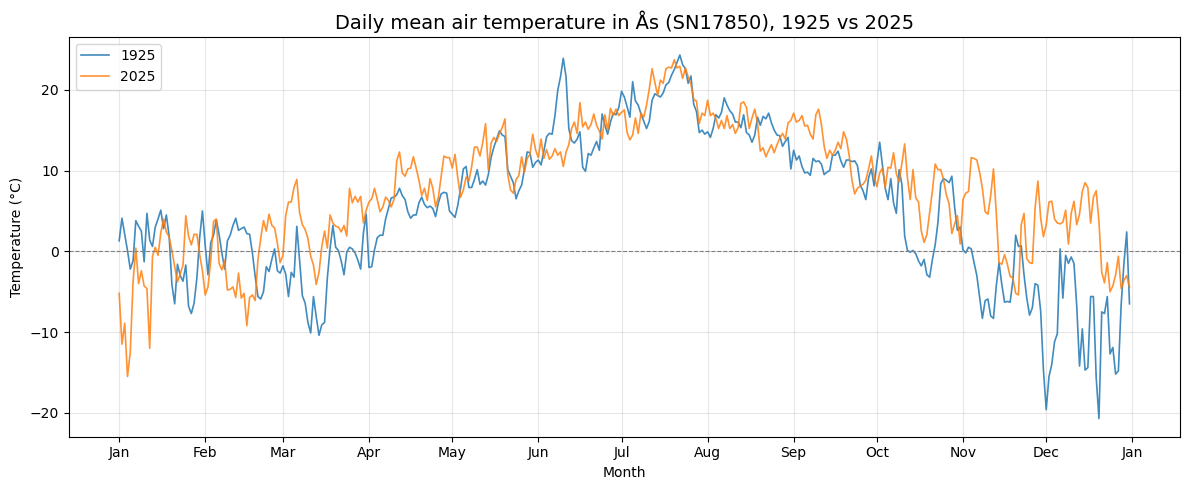

In [3]:
main()

## Discussion

### Task 1: Temperature

- The daily mean temperature in Ås in 2025 follows the seasons. It is lowest in January and December and highest in July.
- The mean for the year was 7.9 °C and the median was 8.3 °C. The coldest day had a mean temperature of −15.5 °C and the warmest day had 23.7 °C.
- The median is higher than the mean. This is probably because the few very cold days in winter affect the mean more than the median.

### Task 2: Precipitation

- Precipitation is an amount per day, so we used bars for it and a line for temperature. Precipitation has its own y-axis on the right, because the two measurements have different units (mm and °C).
- Most days have little or no precipitation, while a few days have heavy precipitation (up to about 35 mm).
- We cannot see a clear connection between temperature and precipitation in the plot. There is precipitation in all seasons.

### Task 3: Temperature in 1925 and 2025

| | 1925 (°C) | 2025 (°C) | Difference (°C) |
|---|---|---|---|
| Mean | 5.3 | 7.9 | 2.6 |
| Median | 5.3 | 8.3 | 3.0 |
| Min | −20.7 | −15.5 | 5.2 |
| Max | 24.3 | 23.7 | −0.6 |

- 2025 was 2.6 °C warmer than 1925 on average. The largest difference is in winter: the coldest day in 1925 was 5.2 °C colder than the coldest day in 2025.
- The summer temperatures are almost the same, and the warmest day was slightly warmer in 1925.
- The results should be interpreted with caution, since we only compare two single years. Weather varies a lot from year to year, so this does not show a long-term trend. The measuring equipment and the exact location of the station may also have been different 100 years ago.

In [4]:
client_id = read_client_id(CLIENT_ID_PATH)
df_2025 = make_dataframe(
    fetch_data(client_id, STATION, TEMPERATURE, whole_year(2025)))
print('Number of days (temperature 2025):', len(df_2025))

Data retrieved: mean(air_temperature P1D), 2025-01-01/2026-01-01
Number of days (temperature 2025): 365


In [5]:
import yaml

HEATWAVE_LIMIT = 27.0  # in °C
MIN_HEATWAVE_DAYS = 5
MAX_TEMPERATURE = 'max(air_temperature P1D)'


def find_heatwaves(
    df: pd.DataFrame,
) -> list[tuple[pd.Timestamp, pd.Timestamp]]:
    """Find heatwaves: 5+ days in a row with max temp of 27 °C or more."""
    streaks = []
    current = []  # the hot days in a row so far
    for day, max_temp in zip(df['referenceTime'], df['value']):
        # if a day is missing in the data, the streak is broken
        if current and day - current[-1] != pd.Timedelta(days=1):
            streaks.append(current)
            current = []
        if max_temp >= HEATWAVE_LIMIT:
            current.append(day)
        else:
            streaks.append(current)
            current = []
    streaks.append(current)  # the last streak can go to the end of the year
    return [(streak[0], streak[-1]) for streak in streaks
            if len(streak) >= MIN_HEATWAVE_DAYS]


def write_heatwave_summary(client_id: str, station_id: str,
                           station_name: str, year: int) -> int:
    """Write a yml summary of the heatwaves and return how many there are."""
    # station and year are arguments, so it works for any of them
    data = fetch_data(client_id, station_id, MAX_TEMPERATURE, whole_year(year))
    heatwaves = find_heatwaves(make_dataframe(data))
    # same keys as in the example file (yaml.dump sorts them like that too)
    summary = {
        'dates': [f'{start:%Y-%m-%d} - {end:%Y-%m-%d}'
                  for start, end in heatwaves],
        'station_id': station_id,
        'station_name': station_name,
        'year': year,
    }
    with open(f'heatwave_summary_{station_id}_{year}.yml', 'w') as yml_file:
        yaml.dump(summary, yml_file)
    return len(heatwaves)


number_of_heatwaves = write_heatwave_summary(client_id, STATION, 'Ås', 2025)
print(f'Number of heatwaves in Ås in 2025: {number_of_heatwaves}')

Data retrieved: max(air_temperature P1D), 2025-01-01/2026-01-01
Number of heatwaves in Ås in 2025: 1


In [6]:
with open('heatwave_summary_SN17850_2025.yml') as f:
    print(f.read())

dates:
- 2025-07-16 - 2025-07-20
station_id: SN17850
station_name: "\xC5s"
year: 2025



In [7]:
raw = fetch_data(client_id, STATION, 'max(air_temperature P1D)', whole_year(2025))
all_obs = pd.concat(
    [pd.DataFrame(day['observations']).assign(referenceTime=day['referenceTime'])
     for day in raw], ignore_index=True)
all_obs['referenceTime'] = pd.to_datetime(all_obs['referenceTime'])
for offset, group in all_obs.groupby('timeOffset'):
    print(offset, len(group), find_heatwaves(group))

Data retrieved: max(air_temperature P1D), 2025-01-01/2026-01-01
PT0H 364 [(Timestamp('2025-07-16 00:00:00+0000', tz='UTC'), Timestamp('2025-07-20 00:00:00+0000', tz='UTC'))]
PT18H 365 [(Timestamp('2025-07-16 00:00:00+0000', tz='UTC'), Timestamp('2025-07-22 00:00:00+0000', tz='UTC'))]


### Task 4: Heatwaves

We used the daily maximum temperature (`max(air_temperature P1D)`) for Ås in 2025. A heatwave is defined as five or more consecutive days with a maximum temperature of at least 27 °C.

**Method**
- `find_heatwaves()` goes through the days in order and collects consecutive days with a maximum temperature of at least 27 °C.
- A streak ends if a day is below 27 °C or if a day is missing in the data.
- Streaks of five days or more are saved with a start date and an end date.
- `write_heatwave_summary()` takes the station ID, the station name and the year as arguments, so it works for any station and year. The result is written to a yml file.

**Result**
- We found one heatwave in 2025, from 16 to 20 July, with maximum temperatures between 28.3 and 30.8 °C.
- There were more hot days before and after this period (11–12 July, 22 July and 24–25 July), but never five days in a row.

**Notes**
- Frost returns two values per day for the maximum temperature, and `make_dataframe()` keeps the first one. This is almost always `PT0H` (midnight to midnight).
- When we used only the `PT18H` values, we also found one heatwave, but it ended on 22 July instead of 20 July. The number of heatwaves is therefore the same, but the end date depends on which 24-hour period is used.
- The example file in the assignment shows other dates (two heatwaves). We could not reproduce these dates with either series, so we assume the file is only meant to show the format.

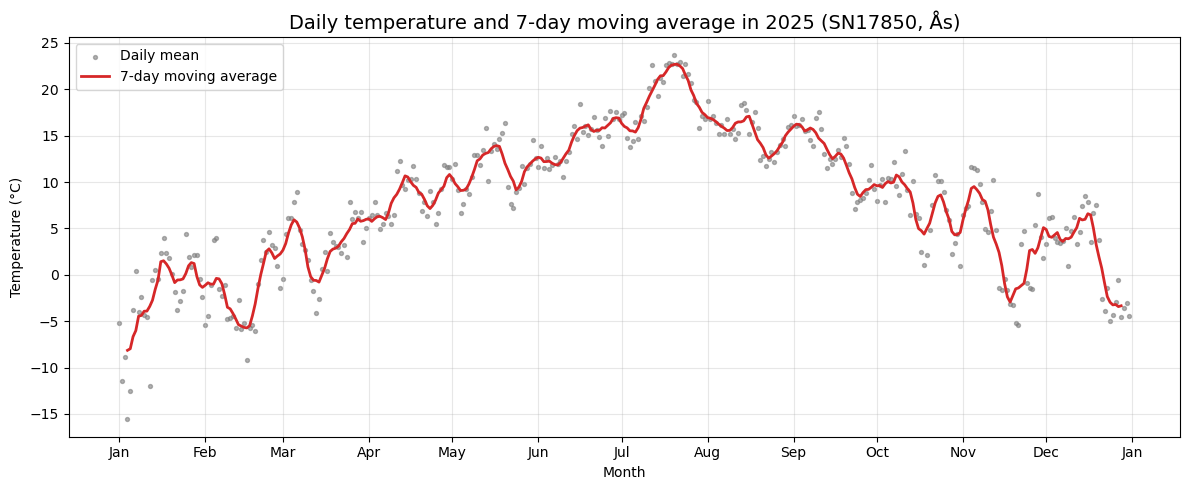

In [8]:
def moving_average(values: pd.Series, window: int = 7) -> pd.Series:
    """Calculate the moving average of a series over a number of days."""
    # center=True puts the average on the middle day of the window, so the
    # line is not moved to the side. The first and last 3 days become NaN
    # since they don't have 7 days around them
    return values.rolling(window=window, center=True).mean()


df_2025['moving_average'] = moving_average(df_2025['value'], window=7)

fig, ax = plt.subplots(figsize=(12, 5))
# points for the daily values, line for the moving average
ax.scatter(df_2025['referenceTime'], df_2025['value'], s=8,
           color='tab:gray', alpha=0.6, label='Daily mean')
ax.plot(df_2025['referenceTime'], df_2025['moving_average'],
        color='tab:red', linewidth=2, label='7-day moving average')
ax.set_title('Daily temperature and 7-day moving average in 2025 '
             '(SN17850, Ås)', fontsize=14)
ax.set_xlabel('Month')
ax.set_ylabel('Temperature (°C)')
# only month names on the x-axis, like in the other plots
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.grid(alpha=0.3)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Task 5: Moving average

- `moving_average()` uses `rolling(window=7, center=True).mean()` on the daily mean temperature.
- We used `center=True` so that each average is placed on the middle day of its seven-day window. Without it, the line would be shifted a few days compared to the daily values.
- The first and last three days of the year have no value, because they do not have a full window of seven days.
- In the plot, the daily temperatures are shown as points and the moving average as a line. The line is much smoother, which makes the seasonal pattern easier to see: cold in winter, warmest in summer and colder again in autumn. The points show that individual days can differ clearly from the average.
- A limitation is that a 7-day moving average smooths out short events, such as a single very warm or cold day.